# 05 Modelling

This notebook corresponds to the **Machine Learning Modelling** stage.

Goals:
- Predict station imbalance 30 minutes ahead for Dublin Bikes
- explain the overall behavior of the system


In this notebook we use regression modelling: Random Forrest, XGBoost, Linear

In [3]:
import torch
import time


print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

x = torch.rand(3000, 3000, device=device)
y = torch.rand(3000, 3000, device=device)

torch.cuda.synchronize()
t0 = time.time()
z = x @ y
torch.cuda.synchronize()
t1 = time.time()

print("Result device:", z.device)
print("Elapsed:", t1 - t0, "seconds")

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED) 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

torch: 2.10.0+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU
Using: cuda
Result device: cuda:0
Elapsed: 0.19137191772460938 seconds


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score


from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    classification_report,
    roc_auc_score
)


import matplotlib.pyplot as plt
import seaborn as sns


## 1. Load engineered dataset with trend

In [5]:


PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
df.head()

(13513883, 18)


,station_id,last_reported,hour_slot,hour_sin,hour_cos,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,util_slope,util_vs_mean,time_slot_str,empty_risk,full_risk,center_index,area_type_str
0,1,2022-04-27 13:00:02,13,-0.258819,-0.965926,2,True,0.0,0.0,0.0,0.870968,NaN,0.0,13:00,True,False,1,retail
1,1,2022-04-27 13:30:02,13,-0.382683,-0.923880,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,13:30,True,False,1,retail
2,1,2022-04-27 14:00:02,14,-0.500000,-0.866025,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,14:00,True,False,1,retail
3,1,2022-04-27 14:30:02,14,-0.608761,-0.793353,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,14:30,True,False,1,retail
4,1,2022-04-27 15:00:02,15,-0.707107,-0.707107,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,15:00,True,False,1,retail


## 2. Create targets


Due to irregular sampling intervals, the target variable was defined as the utilisation at the first available observation occurring at least 30 minutes after the current timestamp. This introduces slight variability in the prediction horizon but avoids interpolation artifacts.

In [ ]:
# target variable: utilisation 30 min in the future

df = df.sort_values(["station_id", "last_reported"]).copy()

def get_target(group):
    group = group.sort_values("last_reported").copy()

    # preserve station_id explicitly
    sid = group["station_id"].iloc[0]

    times = group["last_reported"].to_numpy()
    values = group["utilisation"].to_numpy()

    target = np.full(len(group), np.nan)

    for i in range(len(times)):
        t_future = times[i] + np.timedelta64(30, "m")
        idx = np.searchsorted(times, t_future, side="left")
        if idx < len(times):
            target[i] = values[idx]

    group["utilisation_tplus_30"] = target
    group["station_id"] = sid
    return group

parts = []
for _, g in df.groupby("station_id", sort=False):
    parts.append(get_target(g))

df = pd.concat(parts, ignore_index=True)
print(df.shape)
print(df.columns)



  

(13513883, 19)
Index(['station_id', 'last_reported', 'hour_slot', 'hour_sin', 'hour_cos',
       'days_of_week', 'is_weekday', 'roll_mean_30min', 'roll_std_30min',
       'utilisation', 'dock_ratio', 'util_slope', 'util_vs_mean',
       'time_slot_str', 'empty_risk', 'full_risk', 'center_index',
       'area_type_str', 'utilisation_tplus_30'],
      dtype='str')


In [7]:
# df.info()

print(df.columns)
print(df.index.names)

Index(['station_id', 'last_reported', 'hour_slot', 'hour_sin', 'hour_cos',
       'days_of_week', 'is_weekday', 'roll_mean_30min', 'roll_std_30min',
       'utilisation', 'dock_ratio', 'util_slope', 'util_vs_mean',
       'time_slot_str', 'empty_risk', 'full_risk', 'center_index',
       'area_type_str', 'utilisation_tplus_30'],
      dtype='str')
[None]


## 3. Drop missing rows

The dataset is not missing many observations over 30 minutes intervalls: the worse station has only 0.0126% missing rows

count    115.000000 stations

mean       0.000033 

std        0.000010 

min        0.000022 

25%        0.000027

50%        0.000033

75%        0.000035

max        0.000126



In [8]:
# Count na per station
na_per_station = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .apply(lambda x: x.isna().sum())
      .reset_index(name="na_count")
)

# Add total rows per station
counts = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .size()
      .reset_index(name="total_rows")
)

na_stats = na_per_station.merge(counts, on="station_id")

# Percentage of na 
na_stats["na_ratio"] = na_stats["na_count"] / na_stats["total_rows"]

# worst stations with most na in target
na_stats.sort_values("na_ratio", ascending=False).head(10)
problematic = na_stats[na_stats["na_ratio"] > 0.5]
print(problematic)
print(na_stats["na_ratio"].describe())


# Drop rows with na in target
df = df.dropna(subset=["utilisation_tplus_30", "util_slope", "util_vs_mean"])


Empty DataFrame
Columns: [station_id, na_count, total_rows, na_ratio]
Index: []
count    115.000000
mean       0.000033
std        0.000010
min        0.000022
25%        0.000027
50%        0.000033
75%        0.000035
max        0.000126
Name: na_ratio, dtype: float64


## 4. Feature list and target definition

In [9]:
# Features

features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    # "hour_slot",
    "hour_sin", 
    "hour_cos",
    "is_weekday",
    "center_index",
    'area_type_str',
    "util_slope", # trend of utilisation in last 30 min
    "util_vs_mean", # utilisation vs mean of station in last 30 min
    # "station_cluster"   # if added after Maxime's clustering
]
# One‑hot encode area type and center index

X = df[features]
X = pd.get_dummies(X, columns=['area_type_str', "center_index"], drop_first=True)

y = df["utilisation_tplus_30"]
print("Target variable:")
print(y.describe())
print("Missing values in target:", y.isna().sum())


Target variable:
count    1.350982e+07
mean     3.800239e-01
std      3.047142e-01
min      0.000000e+00
25%      1.000000e-01
50%      3.250000e-01
75%      6.000000e-01
max      1.000000e+00
Name: utilisation_tplus_30, dtype: float64
Missing values in target: 0


## 6. Multicollineartiy diagnostics

### 6.1 Correlation heatmap

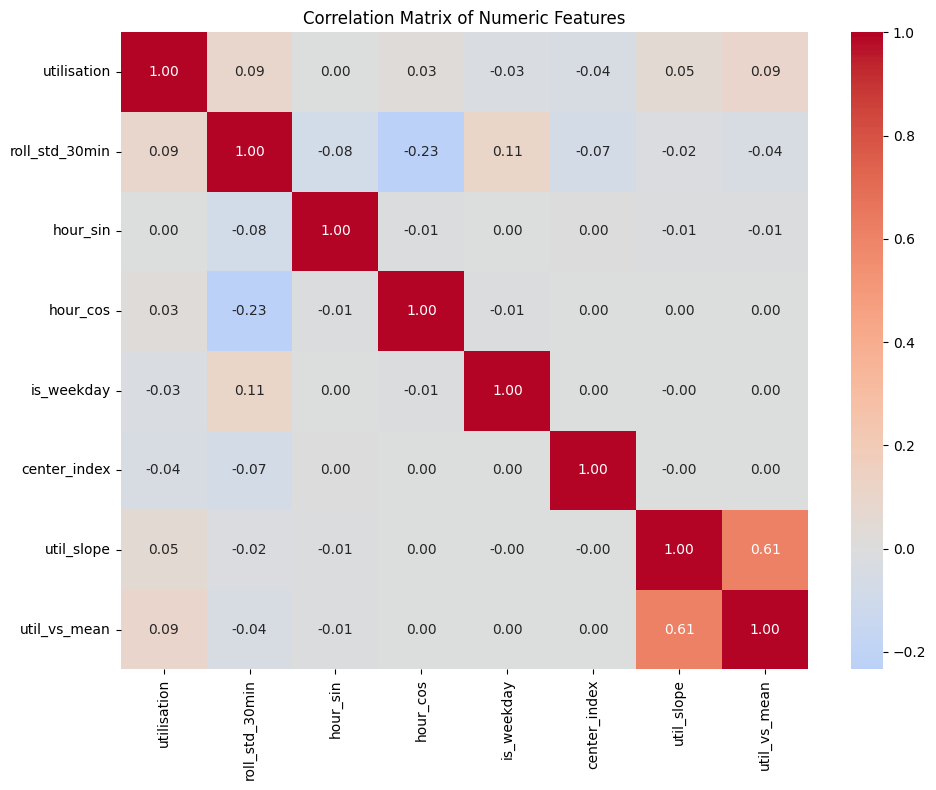

util_vs_mean    util_slope        0.610689
util_slope      util_vs_mean      0.610689
roll_std_30min  hour_cos          0.233955
hour_cos        roll_std_30min    0.233955
roll_std_30min  is_weekday        0.105008
is_weekday      roll_std_30min    0.105008
util_vs_mean    utilisation       0.094863
utilisation     util_vs_mean      0.094863
                roll_std_30min    0.091850
roll_std_30min  utilisation       0.091850
hour_sin        roll_std_30min    0.082432
roll_std_30min  hour_sin          0.082432
                center_index      0.073025
center_index    roll_std_30min    0.073025
util_slope      utilisation       0.054021
dtype: float64


In [55]:
numeric_features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    # "hour_slot",
    "hour_sin", 
    "hour_cos",
    "is_weekday",
    "center_index",
    "util_slope",
    "util_vs_mean",
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()


corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]

print(corr_pairs.head(15))

### 6.2 VIF on sampled encoded feature matrix

In [56]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# Use the encoded feature matrix already prepared for modelling
X_vif = X.copy()

# Remove missing values just in case
X_vif = X_vif.dropna().copy()

# Sample for speed
sample_size = min(50000, len(X_vif))
X_vif_sample = X_vif.sample(sample_size, random_state=42)

# Ensure numeric dtype
X_vif_sample = X_vif_sample.astype(float)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif_sample.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif_sample.values, i)
    for i in range(X_vif_sample.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)
vif_data.head(15)


# flag feature with high VIF
high_vif = vif_data[vif_data["VIF"] > 5].copy()
print("Features with VIF > 5:")
print(high_vif.to_string(index=False))

Features with VIF > 5:
Empty DataFrame
Columns: [feature, VIF]
Index: []


### VIF first run with all features:
`Features with VIF > 5:

feature:          VIF
-    utilisation:         inf
- roll_mean_30min:         inf
- util_vs_mean: 9.007199e+15
- center_index: 1.038968e+01
- dock_ratio: 8.105422e+00`

Variance Inflation Factor (VIF) analysis revealed perfect multicollinearity between utilisation, rolling mean, and deviation-from-mean features, due to a deterministic linear relationship. To resolve this, rolling mean was removed while retaining utilisation and deviation features, preserving interpretability and predictive information.
We also removed dock_ratio as complemenraty of utilisation.

### After removing dock_ratio and roll_mean_30min
Features with VIF > 5:
     feature      VIF
center_index 5.192763

which is acceptable.

## 7. Train/test split

In [10]:

# Time‑based split: last 365 days as test
cutoff = df['last_reported'].max() - pd.Timedelta(days=365)
train_mask = df['last_reported'] < cutoff

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]


In [13]:
print("NaN in y_test:", pd.isna(y_test).sum())

print("NaN in X_train:", np.isnan(X_train).sum())
print("NaN in X_test:", np.isnan(X_test).sum())

print("Inf in X_train:", np.isinf(X_train).sum())
print("Inf in X_test:", np.isinf(X_test).sum())

NaN in y_test: 0
NaN in X_train: utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
area_type_str_retail    0
area_type_str_work      0
center_index_2          0
center_index_3          0
dtype: int64
NaN in X_test: utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
area_type_str_retail    0
area_type_str_work      0
center_index_2          0
center_index_3          0
dtype: int64
Inf in X_train: utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
area_type_str_retail    0
area_type_str_work      0
center_index_2          0
center_index_3          0
dtype: int64
Inf in X_test: utilisation             

## 8. Random Forest regressor

In [60]:
RANDOM_SEED = 42
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)


# Evaluation
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = root_mean_squared_error(y_test, y_pred_rf)

print(f"Random Forest MAE: {mae:.4f}")
print(f"Random Forest RMSE: {rmse:.4f}")

# Conversion to empty/full bands
EMPTY_THRESHOLD = 0.05
FULL_THRESHOLD  = 0.95

empty_pred_rf = (y_pred_rf < EMPTY_THRESHOLD).astype(int)
full_pred_rf  = (y_pred_rf > FULL_THRESHOLD).astype(int)

empty_true = (y_test < EMPTY_THRESHOLD).astype(int)
full_true  = (y_test > FULL_THRESHOLD).astype(int)


# Evaluation

print("=== RANDOM FOREST - EMPTY ===")
print(classification_report(empty_true, empty_pred_rf))

print("=== RANDOM FOREST - FULL ===")
print(classification_report(full_true, full_pred_rf))

print("EMPTY ROC AUC:", roc_auc_score(empty_true, -y_pred_rf))
print("FULL ROC AUC:", roc_auc_score(full_true, y_pred_rf))

# Coefficients inspection
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": rf_model.feature_importances_
}).sort_values("coefficient", key=abs, ascending=False) 
print("Top coefficients:")
print(coef_df.head(20).to_string(index=False))


Random Forest MAE: 0.0420
Random Forest RMSE: 0.0757
=== RANDOM FOREST - EMPTY ===
              precision    recall  f1-score   support

           0       0.96      0.98      0.97   5734721
           1       0.86      0.76      0.81   1047906

    accuracy                           0.94   6782627
   macro avg       0.91      0.87      0.89   6782627
weighted avg       0.94      0.94      0.94   6782627

=== RANDOM FOREST - FULL ===
              precision    recall  f1-score   support

           0       0.98      0.99      0.99   6432061
           1       0.85      0.56      0.67    350566

    accuracy                           0.97   6782627
   macro avg       0.91      0.78      0.83   6782627
weighted avg       0.97      0.97      0.97   6782627

EMPTY ROC AUC: 0.9714068898124443
FULL ROC AUC: 0.9823124409909776
Top coefficients:
             feature  coefficient
         utilisation     0.994688
          util_slope     0.001418
            hour_cos     0.001182
            h

## 9. XGBoost Regression

In [14]:
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)


# Predictions

y_pred_xgb = xgb_model.predict(X_test)


# Evaluation
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = root_mean_squared_error(y_test, y_pred_xgb)

print(f"XGBoost MAE: {mae:.4f}")
print(f"XGBoost RMSE: {rmse:.4f}")

# Conversion to empty/full bands
EMPTY_THRESHOLD = 0.05
FULL_THRESHOLD  = 0.95

empty_pred_xgb = (y_pred_xgb < EMPTY_THRESHOLD).astype(int)
full_pred_xgb  = (y_pred_xgb > FULL_THRESHOLD).astype(int)

empty_true = (y_test < EMPTY_THRESHOLD).astype(int)
full_true  = (y_test > FULL_THRESHOLD).astype(int)


# Evaluation

print("=== XGBOOST - EMPTY ===")
print(classification_report(empty_true, empty_pred_xgb))

print("=== XGBOOST - FULL ===")
print(classification_report(full_true, full_pred_xgb))

print("EMPTY ROC AUC:", roc_auc_score(empty_true, -y_pred_xgb))
print("FULL ROC AUC:", roc_auc_score(full_true, y_pred_xgb))

# Coefficients inspection
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": xgb_model.feature_importances_
}).sort_values("coefficient", key=abs, ascending=False) 
print("Top coefficients:")
print(coef_df.head(20).to_string(index=False))


XGBoost MAE: 0.0416
XGBoost RMSE: 0.0744
=== XGBOOST - EMPTY ===
              precision    recall  f1-score   support

           0       0.96      0.97      0.97   5734721
           1       0.83      0.78      0.81   1047906

    accuracy                           0.94   6782627
   macro avg       0.90      0.88      0.89   6782627
weighted avg       0.94      0.94      0.94   6782627

=== XGBOOST - FULL ===
              precision    recall  f1-score   support

           0       0.98      0.99      0.99   6432061
           1       0.85      0.55      0.67    350566

    accuracy                           0.97   6782627
   macro avg       0.91      0.77      0.83   6782627
weighted avg       0.97      0.97      0.97   6782627

EMPTY ROC AUC: 0.9720922211546948
FULL ROC AUC: 0.9831181233619463
Top coefficients:
             feature  coefficient
         utilisation     0.879127
area_type_str_retail     0.049829
      center_index_2     0.019327
          is_weekday     0.013453
   

## 10. Scaling

Feature scaling was applied for linear models to ensure comparable feature magnitudes, while tree-based models were trained on raw features as they are invariant to scaling.

In [ ]:

# Scale features (except one‑hot)
scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("Train shape:", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)

'\n# Scale features (except one‑hot)\nscaler = StandardScaler(with_mean=False)\nX_train_scaled = scaler.fit_transform(X_train)\nX_test_scaled = scaler.transform(X_test)\n\n\nprint("Train shape:", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)'


## 12. Linear model

In [61]:


RANDOM_SEED = 42
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)


# Predictions
y_pred_lin = lin_model.predict(X_test)
# Evaluation
mae = mean_absolute_error(y_test, y_pred_lin)
rmse = root_mean_squared_error(y_test, y_pred_lin)

print(f"Linear Regression MAE: {mae:.4f}")
print(f"Linear Regression RMSE: {rmse:.4f}")

# Conversion to empty/full bands
EMPTY_THRESHOLD = 0.05
FULL_THRESHOLD  = 0.95

empty_pred_lin = (y_pred_lin < EMPTY_THRESHOLD).astype(int)
full_pred_lin  = (y_pred_lin > FULL_THRESHOLD).astype(int)

empty_true = (y_test < EMPTY_THRESHOLD).astype(int)
full_true  = (y_test > FULL_THRESHOLD).astype(int)


# Evaluation

print("=== LINEAR - EMPTY ===")
print(classification_report(empty_true, empty_pred_lin))

print("=== LINEAR - FULL ===")
print(classification_report(full_true, full_pred_lin))

print("EMPTY ROC AUC:", roc_auc_score(empty_true, -y_pred_lin))
print("FULL ROC AUC:", roc_auc_score(full_true, y_pred_lin))

# Coefficients inspection
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lin_model.coef_
}).sort_values("coefficient", key=abs, ascending=False) 
print("Top coefficients:")
print(coef_df.head(20).to_string(index=False))


Linear Regression MAE: 0.2570
Linear Regression RMSE: 0.3019
=== LINEAR - EMPTY ===


/home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` par

              precision    recall  f1-score   support

           0       0.85      1.00      0.92   5734721
           1       0.00      0.00      0.00   1047906

    accuracy                           0.85   6782627
   macro avg       0.42      0.50      0.46   6782627
weighted avg       0.71      0.85      0.77   6782627

=== LINEAR - FULL ===


/home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/tbeliere/Projects/DCU/2026-csc1144-dublin-bikes/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` par

              precision    recall  f1-score   support

           0       0.95      1.00      0.97   6432061
           1       0.00      0.00      0.00    350566

    accuracy                           0.95   6782627
   macro avg       0.47      0.50      0.49   6782627
weighted avg       0.90      0.95      0.92   6782627

EMPTY ROC AUC: 0.5801992606613747
FULL ROC AUC: 0.6658214420792526
Top coefficients:
             feature  coefficient
      center_index_2    -0.067745
      center_index_3     0.059095
            hour_cos     0.017019
         utilisation     0.008591
area_type_str_retail     0.006298
  area_type_str_work     0.006211
            hour_sin     0.001268
          is_weekday    -0.000338
        util_vs_mean     0.000019
      roll_std_30min     0.000007
          util_slope     0.000003
